In [1]:
import sys
sys.path.append('../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import norm

In [2]:
# Create solitons
L = 20
N = 2000
k = 1/4

pars = {"k":k}

c_1 = 0
c_2 = np.sqrt(2)/2

# Theretical solitons
w_dark, x_dark = soliton(c_1, k, soliton_type="dark", L=L, N=N, as_func=True) #c=0
w_bright, x_bright = soliton(c_2, k, soliton_type="bright", L=L, N=N, as_func=True) #c=0

Creating soliton...


/Users/sebatapia/Desktop/Phd/Nonlinear_Schrodinger/Tests/QGP/../../QGP/Soliton_Gen.py:219: RuntimeWarning: Results obtained with less than 2 decimal digits of accuracy
  warnings.warn("Results obtained with less than %g "


Soliton created
Creating soliton...
Soliton created


In [21]:
dt = 0.005
tf = 3

w_comp = Complex_CNFD(L, N, dt, tf, pars, "neumann")
w_comp.set_init_condition(w_dark)
w_comp.solve()

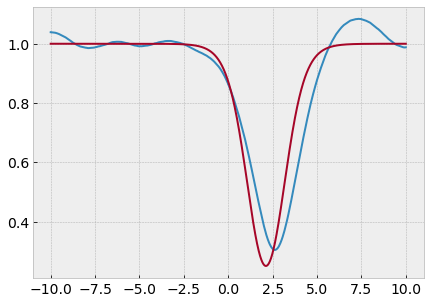

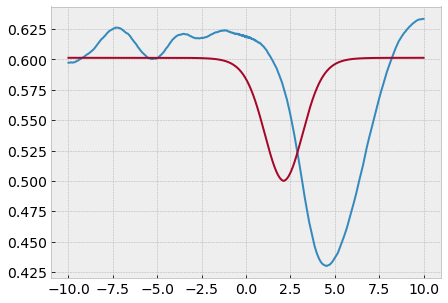

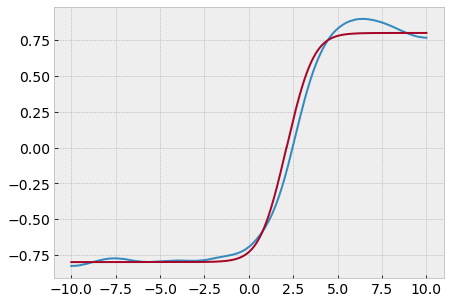

In [23]:
w_comp.plot(tf)
plt.plot(x_dark, norm(w_dark(x_dark-c_2*tf)))
plt.show()

w_comp.plot_real(tf)
plt.plot(x_dark, np.real(w_dark(x_dark-c_2*tf)))
plt.show()

w_comp.plot_imag(tf)
plt.plot(x_dark, np.imag(w_dark(x_dark-c_2*tf)))
plt.show()

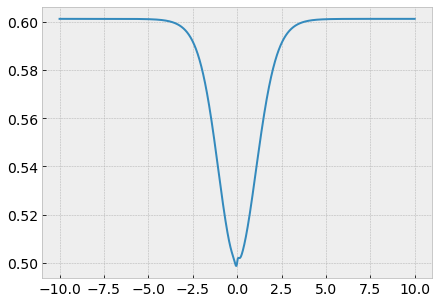

In [31]:
j = 1
t_plot = j * dt
w_comp.plot_real(t_plot)
#plt.plot(x_dark, np.real(w_dark(x_dark-c_2*t_plot)))
plt.show()

In [3]:
dt = 0.01
tf = 5

w_comp = Foc.CNFD(L, N, dt, tf, pars, "neumann")
w_comp.set_init_condition(w_bright)
w_comp.solve()

In [4]:
def bright_soliton(x, t, c=c_2):
    i = 1j
    output = w_bright(x) * np.exp(-i * c * t)
    return output

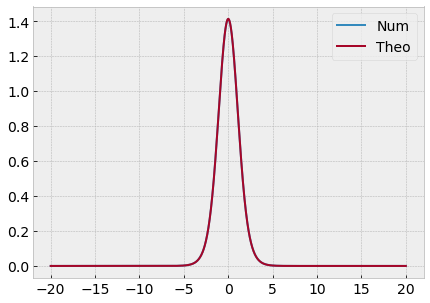

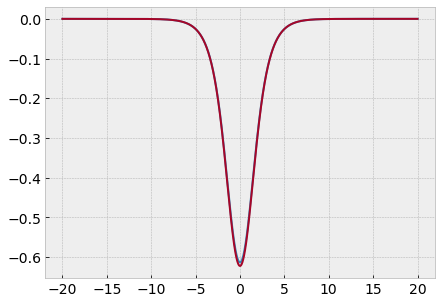

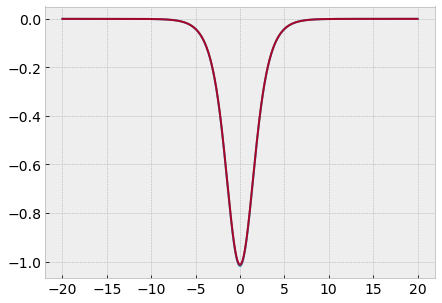

In [39]:
j = 300
t_plot = dt * j

w_comp.plot(t_plot, label="Num")
plt.plot(x_bright, norm(bright_soliton(x_bright, t_plot, c_2)), label="Theo")
plt.legend()
plt.show()

w_comp.plot_real(t_plot, label="Num")
plt.plot(x_bright, np.real(bright_soliton(x_bright, t_plot, c_2)), label="Theo")
plt.show()

w_comp.plot_imag(t_plot, label="Num")
plt.plot(x_bright, np.imag(bright_soliton(x_bright, t_plot, c_2)), label="Theo")
plt.show()

In [5]:
w_comp.w_theo = bright_soliton

MovieWriter ffmpeg unavailable; using Pillow instead.


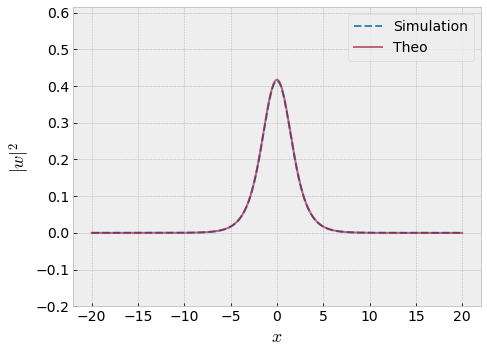

In [13]:
w_comp.animate_solution("test_imag.gif", 5, theo=True, coord="imag")